In [3]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt

import visualizing_functions as visualizer


In [5]:
all_df = pd.read_csv('parsed_data/shapes.csv')

all_df.head()

,session_id,participant_id,image_filename,image_path,canvas_width,canvas_height,image_type,trial_type,condition,trial_index,...,fill,opacity,bbox_tl_x,bbox_tl_y,bbox_br_x,bbox_br_y,point_coordinates,points,transformed_points,vertices
0,2026-09-21_17h18.45.543,P_2026-09-21_17h18.45.543,NAT04_1lemonade_01b.jpg,NAT_SET/NAT04_1lemonade_01b.jpg,667.0,667.000000,Nat,ELA,Emphasis,9,...,#111111,0.5,232.5,232.500000,434.5,434.500000,"[(233.5, 233.5), (433.5, 433.5), (233.5, 433.5)]","[{'x': 233.5, 'y': 233.5}, {'x': 433.5, 'y': 4...","[{'x': 567, 'y': 567}, {'x': 767, 'y': 767}, {...","[{'x': 233.5, 'y': 233.5}, {'x': 433.5, 'y': 4..."
1,2026-09-21_17h18.45.543,P_2026-09-21_17h18.45.543,NAT37_TS_image_79.png,NAT_SET/NAT37_TS_image_79.png,1000.0,660.954712,Nat,ELA,Emphasis,10,...,#111111,0.5,399.0,229.477356,601.0,431.477356,"[(400, 230.47735618115053), (600, 430.47735618...","[{'x': 400, 'y': 230.47735618115053}, {'x': 60...","[{'x': 900, 'y': 560.954712362301}, {'x': 1100...","[{'x': 400, 'y': 230.47735618115053}, {'x': 60..."
2,2026-09-21_17h18.45.543,P_2026-09-21_17h18.45.543,NAT34_TS_image_61.png,NAT_SET/NAT34_TS_image_61.png,1000.0,730.717185,Nat,ELA,Emphasis,11,...,#111111,0.5,489.0,354.358593,511.0,376.358593,"[(510, 365.35859269282815), (509.2387953251128...","[{'x': 510, 'y': 365.35859269282815}, {'x': 50...","[{'x': 1010, 'y': 730.7171853856563}, {'x': 10...","[{'x': 510, 'y': 365.35859269282815}, {'x': 50..."
3,2026-09-21_17h18.45.543,P_2026-09-21_17h18.45.543,NAT30_TS_image_43.png,NAT_SET/NAT30_TS_image_43.png,1000.0,666.666667,Nat,ELA,Emphasis,12,...,#111111,0.5,399.0,232.333333,601.0,434.333333,"[(400, 233.33333333333331), (600, 433.33333333...","[{'x': 400, 'y': 233.33333333333331}, {'x': 60...","[{'x': 900, 'y': 566.6666666666666}, {'x': 110...","[{'x': 400, 'y': 233.33333333333331}, {'x': 60..."
4,2026-09-21_17h18.45.543,P_2026-09-21_17h18.45.543,NAT36_TS_image_63.png,NAT_SET/NAT36_TS_image_63.png,1000.0,732.203390,Nat,ELA,Emphasis,13,...,#111111,0.5,399.0,265.101695,601.0,467.101695,"[(400, 266.1016949152542), (600, 466.101694915...","[{'x': 400, 'y': 266.1016949152542}, {'x': 600...","[{'x': 900, 'y': 632.2033898305084}, {'x': 110...","[{'x': 400, 'y': 266.1016949152542}, {'x': 600..."


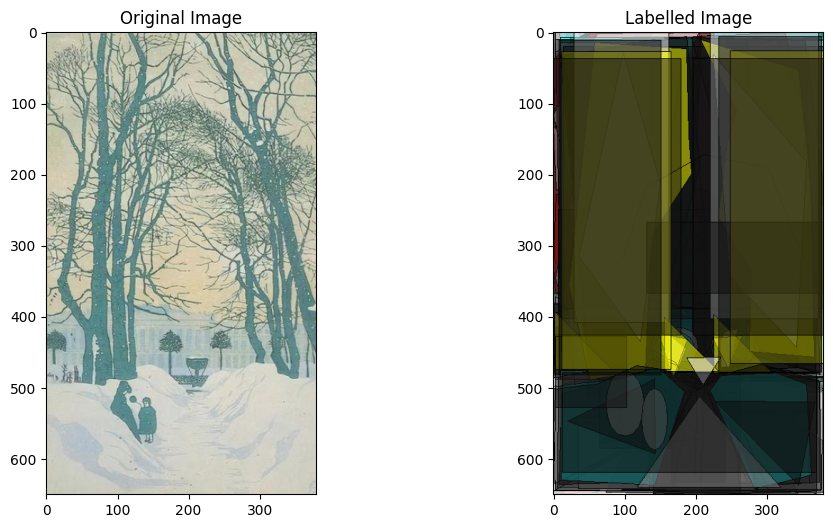

In [9]:
img_file = 'ART10_CL_0002.jpg'
df_img = all_df[all_df['image_filename'] == img_file]

# print(df_img)

img = cv2.imread(visualizer.get_img_path(img_file))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(img)
axs[0].set_title('Original Image')

axs[1].set_title('Labelled Image')
plt.sca(axs[1])
labelled_img = visualizer.label_image(img, df_img, line_thickness=1)
plt.imshow(labelled_img)
plt.show()


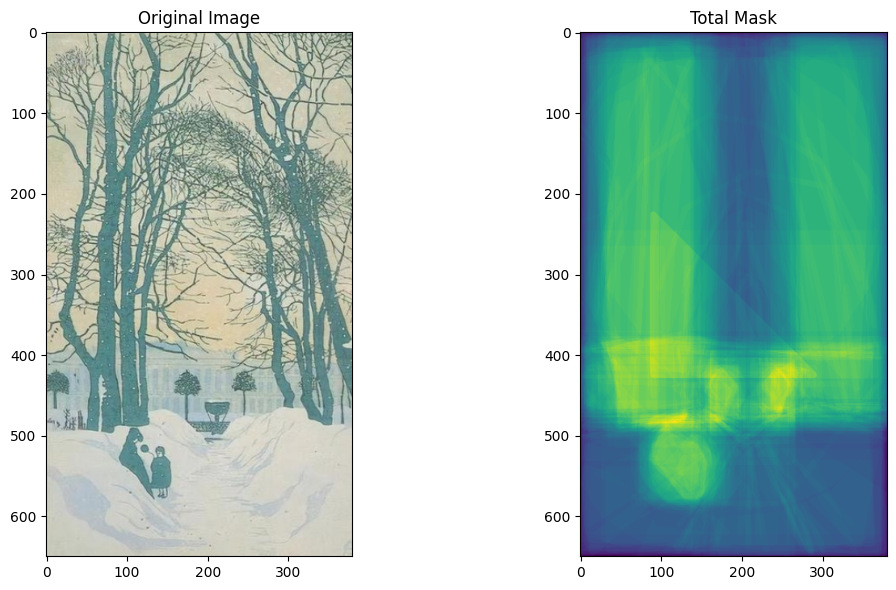

In [7]:
total_mask = visualizer.get_total_mask(img, df_img, line_thickness=5)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(img)
axs[0].set_title('Original Image')
# axs[0].axis('off')

axs[1].imshow(total_mask)
axs[1].set_title('Total Mask')
# axs[1].axis('off')

plt.tight_layout()
plt.show()


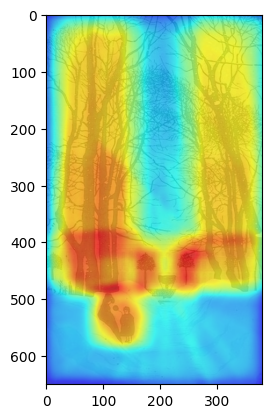

In [8]:
heatmap_img = visualizer.create_heatmap(img, total_mask)
plt.imshow(heatmap_img)
plt.show()